# Experiment 2 — Strategic deconfliction with a fixed obstacle

This experiment evaluates strategic deconfliction when the original UAV flight plan crosses a known fixed obstacle. The same scenario is executed without strategic deconfliction and with the built-in lateral-detour algorithm.

In [1]:
from pathlib import Path

from IPython.display import Image, display

from musas.airspace import Airspace, Cylinder3D, Obstacle
from musas.algorithms import (
    FirstOrderDynamics,
    DetourPathPlanner,
    MinimumSeparationConflictPrediction,
    RecursiveTimeShiftDeconfliction,
    WaypointGuidance,
)
from musas.domain import FlightPlan, Waypoint
from musas.simulation import (
    Simulation,
    SimulationDataset,
    VisualizationConfig,
    animate_dataset,
    calculate_metrics,
    plot_dataset,
)

OUTPUT_DIRECTORY = Path("outputs") / "output_exp2"
DATASET_DIRECTORY = OUTPUT_DIRECTORY / "datasets"
OUTPUT_DIRECTORY.mkdir(parents=True, exist_ok=True)
DATASET_DIRECTORY.mkdir(exist_ok=True)

## Scenario configuration

The proposed flight plan is a straight line through the center of a cylindrical obstacle. The obstacle is known before the proposal is evaluated, so it can be handled strategically.

In [2]:
SIMULATION_END = 45.0
SAMPLING_INTERVAL = 0.25
LATERAL_CLEARANCE = 10.0

def create_flight_plan():
    return FlightPlan([
        Waypoint(-100.0, 0.0, 100.0, 2.0),
        Waypoint(100.0, 0.0, 100.0, 32.0),
    ])

def create_airspace():
    obstacle = Obstacle(
        obstacle_id="central-obstacle",
        name="Central obstacle",
        geometry=Cylinder3D(
            center_x=0.0,
            center_y=0.0,
            radius=20.0,
            minimum_z=90.0,
            maximum_z=110.0,
        ),
    )
    return Airspace(obstacles={obstacle.obstacle_id: obstacle})

## Run the baseline and strategic-deconfliction cases

The baseline disables strategic deconfliction, causing the proposal to be approved unchanged. The SD case uses hybrid lateral/vertical path planning for the obstacle, followed by Recursive Time Shift FCFS if traffic conflicts remain.

In [3]:
CASES = {
    "without_sd": "Without strategic deconfliction",
    "with_sd": "With strategic deconfliction",
}

def run_case(case_name):
    dataset_path = DATASET_DIRECTORY / f"{case_name}.sqlite"
    simulation_arguments = {}

    if case_name == "with_sd":
        conflict_prediction = MinimumSeparationConflictPrediction(
            minimum_separation_distance=20.0,
            sampling_interval=SAMPLING_INTERVAL,
        )
        path_planner = DetourPathPlanner(
            conflict_prediction_algorithm=conflict_prediction,
            lateral_clearance=LATERAL_CLEARANCE,
            vertical_clearance=LATERAL_CLEARANCE,
        )
        deconfliction = RecursiveTimeShiftDeconfliction(
            conflict_prediction_algorithm=conflict_prediction,
            path_planner=path_planner,
        )
        simulation_arguments = {
            "strategic_conflict_prediction_algorithm": conflict_prediction,
            "strategic_deconfliction_algorithm": deconfliction,
        }

    simulation = Simulation(
        airspace=create_airspace(),
        flight_update_interval=0.1,
        trajectory_record_interval=0.2,
        message_types_to_log=(),
        dataset_path=dataset_path,
        dataset_metadata={
            "experiment": "strategic_deconfliction_obstacle",
            "case": case_name,
        },
        overwrite_dataset=True,
        **simulation_arguments,
    )
    simulation.add_uav(
        name="UAV 1",
        flight_plan=create_flight_plan(),
        dynamics_algorithm=FirstOrderDynamics(
            max_acceleration=100.0,
            velocity_time_constant=0.0,
        ),
        guidance_algorithm=WaypointGuidance(
            min_speed=0.0,
            max_speed=15.0,
        ),
        waypoint_acceptance_radius=1.0,
    )
    simulation.run(until=SIMULATION_END)
    simulation.close()
    return dataset_path

dataset_paths = {case_name: run_case(case_name) for case_name in CASES}
dataset_paths

{'without_sd': PosixPath('outputs/output_exp2/datasets/without_sd.sqlite'),
 'with_sd': PosixPath('outputs/output_exp2/datasets/with_sd.sqlite')}

## Metrics

The relevant outputs are the detected strategic conflicts, modified flights, obstacle violations, and the planned and executed distances and times.

In [4]:
print(
    f"{'Case':<38} {'conflicts':>10} {'modified':>10} "
    f"{'violations':>11} {'plan dist.':>12} {'real dist.':>12} "
    f"{'plan time':>11} {'real time':>10}"
)
for case_name, dataset_path in dataset_paths.items():
    with SimulationDataset(dataset_path) as dataset:
        metrics = calculate_metrics(
            dataset,
            minimum_separation_distance=20.0,
            collision_distance=5.0,
        )
    values = metrics["per_uav"]["UAV 1"]
    real_time = values["actual_time"]
    real_time_text = "not completed" if real_time is None else f"{real_time:.1f}"
    print(
        f"{CASES[case_name]:<38} "
        f"{metrics['detected_strategic_conflicts']:10d} "
        f"{metrics['modified_flights']:10d} "
        f"{metrics['obstacle_violations']:11d} "
        f"{values['planned_distance']:12.2f} "
        f"{values['actual_distance']:12.2f} "
        f"{values['planned_time']:11.1f} "
        f"{real_time_text:>10}"
    )

Case                                    conflicts   modified  violations   plan dist.   real dist.   plan time  real time
Without strategic deconfliction                 0          0           1       200.00       198.00        30.0       29.9
With strategic deconfliction                    1          1           0       200.00       209.84        30.0       31.7


## Authorized flight plans

The stored plan versions make the strategic counterproposal explicit.

In [5]:
for case_name, dataset_path in dataset_paths.items():
    with SimulationDataset(dataset_path) as dataset:
        versions = dataset.get_flight_plan_versions("UAV 1")
        plan = dataset.get_flight_plan(
            "UAV 1",
            "authorized",
            versions[-1],
        )
    print(f"\n{CASES[case_name]}:")
    for waypoint in plan.waypoint_list:
        print(
            f"  ({waypoint.x:7.2f}, {waypoint.y:7.2f}, "
            f"{waypoint.z:6.2f}) at t={waypoint.t:6.2f} s"
        )


Without strategic deconfliction:
  (-100.00,    0.00, 100.00) at t=  2.00 s
  ( 100.00,    0.00, 100.00) at t= 32.00 s

With strategic deconfliction:
  (-100.00,    0.00, 100.00) at t=  2.00 s
  ( -30.00,  -30.00, 100.00) at t= 13.42 s
  (  30.00,  -30.00, 100.00) at t= 22.42 s
  ( 100.00,    0.00, 100.00) at t= 33.85 s


## Flight-plan and trajectory figures

These figures are generated directly from each SQLite dataset with `plot_dataset()`.

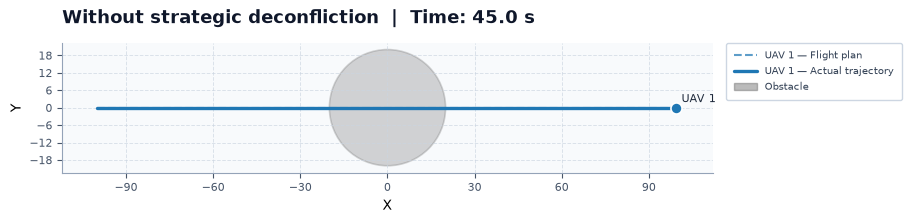

Saved: outputs/output_exp2/without_sd.png


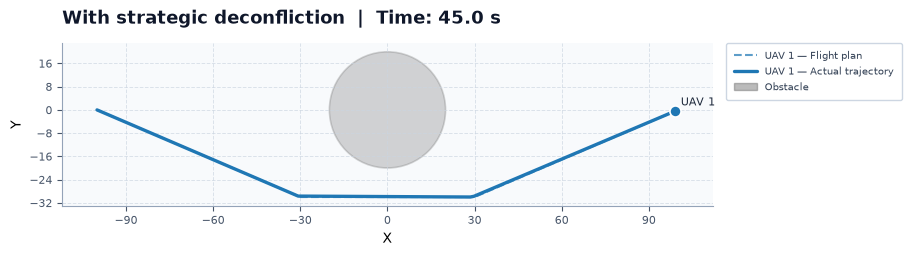

Saved: outputs/output_exp2/with_sd.png


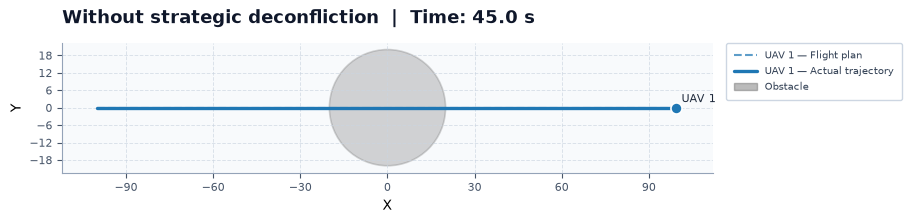

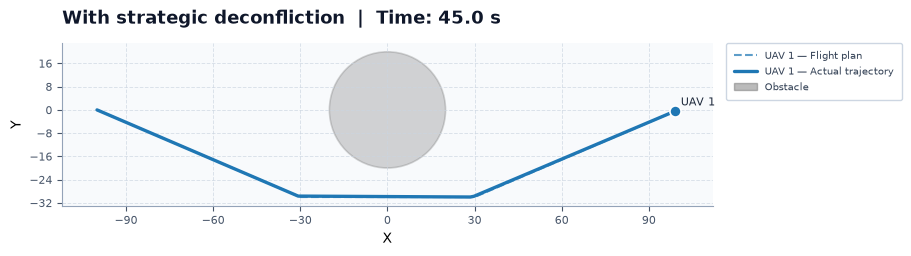

In [6]:
def visualization_config(case_name):
    return VisualizationConfig(
        uav_names=("UAV 1",),
        view="xy",
        show_real_trajectories=True,
        show_current_positions=True,
        show_flight_plans=True,
        show_sensor_reports=False,
        show_tracks=False,
        show_geofences=False,
        show_wind_zones=False,
        show_obstacles=True,
        frame_step=0.5,
        figure_size=(9.0, 6.0),
        title=CASES[case_name],
    )

for case_name, dataset_path in dataset_paths.items():
    figure_path = OUTPUT_DIRECTORY / f"{case_name}.png"
    figure = plot_dataset(
        dataset_path=dataset_path,
        config=visualization_config(case_name),
        timestamp=SIMULATION_END,
        output_path=figure_path,
    )
    display(figure)
    print("Saved:", figure_path)

## Animations

These animations are generated with `animate_dataset()`.

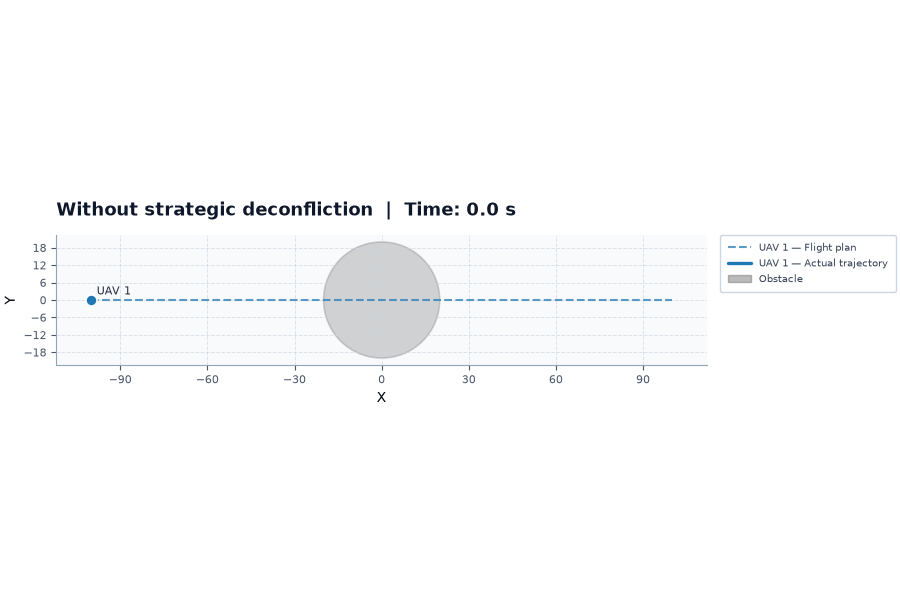

Saved: outputs/output_exp2/without_sd.gif


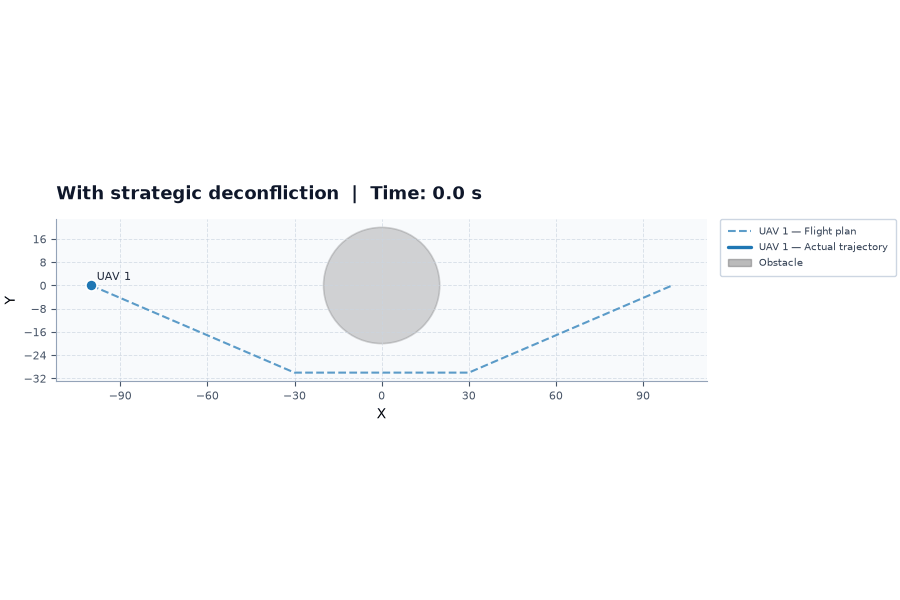

Saved: outputs/output_exp2/with_sd.gif


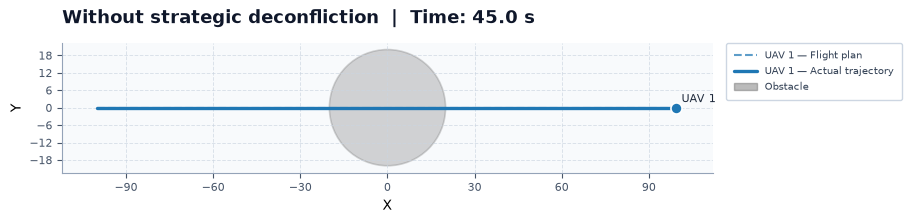

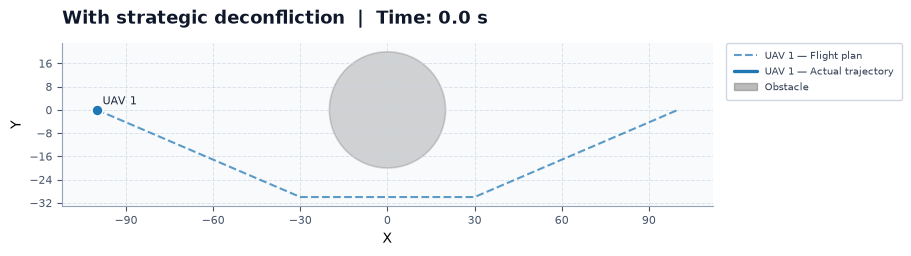

In [7]:
for case_name, dataset_path in dataset_paths.items():
    animation_path = OUTPUT_DIRECTORY / f"{case_name}.gif"
    animate_dataset(
        dataset_path=dataset_path,
        config=visualization_config(case_name),
        output_path=animation_path,
        fps=6.0,
        dpi=100,
    )
    display(Image(filename=animation_path))
    print("Saved:", animation_path)

## Expected interpretation

Without strategic deconfliction, the original straight plan is approved and the UAV enters the obstacle. With strategic deconfliction, the conflict predictor detects the obstacle before departure and the deconfliction algorithm issues a longer lateral counterproposal that avoids the prohibited volume.